# Residential Appliance Energy Consumption Prediction

## Data Understanding and Exploratory Data Analysis

## Project Objective

The objective of this project is to develop and evaluate machine learning
models for predicting residential appliance energy consumption using indoor
environmental measurements, outdoor weather conditions, and temporal
information.

The analysis will investigate the factors associated with appliance energy
demand, evaluate the predictive performance of linear and regularized
regression models, and later compare them with nonlinear machine learning
approaches.

Particular attention will be given to model generalization, data leakage,
feature selection, error analysis, and the operational interpretation of
predictions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\ajibo\OneDrive\Desktop\Linear Regression/energydata_complete.csv")

In [3]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,1/11/2016 17:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,1/11/2016 17:10,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,1/11/2016 17:20,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,1/11/2016 17:30,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,1/11/2016 17:40,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [4]:
df.shape

(19735, 29)

In [5]:
df.columns.tolist()

['date',
 'Appliances',
 'lights',
 'T1',
 'RH_1',
 'T2',
 'RH_2',
 'T3',
 'RH_3',
 'T4',
 'RH_4',
 'T5',
 'RH_5',
 'T6',
 'RH_6',
 'T7',
 'RH_7',
 'T8',
 'RH_8',
 'T9',
 'RH_9',
 'T_out',
 'Press_mm_hg',
 'RH_out',
 'Windspeed',
 'Visibility',
 'Tdewpoint',
 'rv1',
 'rv2']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [7]:
df["Appliances"]

0         60
1         60
2         50
3         50
4         60
        ... 
19730    100
19731     90
19732    270
19733    420
19734    430
Name: Appliances, Length: 19735, dtype: int64

In [8]:
df["Appliances"].head()

0    60
1    60
2    50
3    50
4    60
Name: Appliances, dtype: int64

In [9]:
df["Appliances"].describe()

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

In [10]:
df.isnull().sum()

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [11]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percent": df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percent
date,0,0.0
Appliances,0,0.0
lights,0,0.0
T1,0,0.0
RH_1,0,0.0
T2,0,0.0
RH_2,0,0.0
T3,0,0.0
RH_3,0,0.0
T4,0,0.0


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df["date"].head()

0    1/11/2016 17:00
1    1/11/2016 17:10
2    1/11/2016 17:20
3    1/11/2016 17:30
4    1/11/2016 17:40
Name: date, dtype: str

In [14]:
df["date"] = pd.to_datetime(df["date"])

In [15]:
numeric_df = df.select_dtypes(
    include=np.number
)

np.isinf(numeric_df).sum().sort_values(
    ascending=False
)

Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [16]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Missing values
print("Total missing values:", df.isnull().sum().sum())

# 3. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 4. Data types
print(df.dtypes)

# 5. Convert timestamp
df["date"] = pd.to_datetime(df["date"])

# Timestamp integrity
print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Unique timestamps:", df["date"].nunique())
print("Duplicate timestamps:", df["date"].duplicated().sum())

# 6. Sampling interval
print(
    df["date"]
      .sort_values()
      .diff()
      .value_counts()
      .head()
)

# 7. Numerical summary
display(df.describe().T)

# 8. Constant variables
constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print("Constant columns:", constant_columns)

# 9. Random/noise variables
display(
    df[["rv1", "rv2", "Appliances"]].corr()
)

Dataset shape: (19735, 29)
Total missing values: 0
Duplicate rows: 0
date           datetime64[us]
Appliances              int64
lights                  int64
T1                    float64
RH_1                  float64
T2                    float64
RH_2                  float64
T3                    float64
RH_3                  float64
T4                    float64
RH_4                  float64
T5                    float64
RH_5                  float64
T6                    float64
RH_6                  float64
T7                    float64
RH_7                  float64
T8                    float64
RH_8                  float64
T9                    float64
RH_9                  float64
T_out                 float64
Press_mm_hg           float64
RH_out                float64
Windspeed             float64
Visibility            float64
Tdewpoint             float64
rv1                   float64
rv2                   float64
dtype: object
Start date: 2016-01-11 17:00:00
End date: 2016-

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


Constant columns: []


,rv1,rv2,Appliances
rv1,1.000000,1.000000,-0.011145
rv2,1.000000,1.000000,-0.011145
Appliances,-0.011145,-0.011145,1.000000


In [17]:
print(
    "rv1 and rv2 identical:",
    (df["rv1"] == df["rv2"]).all()
)

print(
    "Maximum absolute difference:",
    (df["rv1"] - df["rv2"]).abs().max()
)

rv1 and rv2 identical: True
Maximum absolute difference: 0.0


## Exploratory Data Analysis

### Distribution of Appliance Energy Consumption

Understanding the distribution of the target variable is important for
identifying typical consumption levels, high-demand periods, potential
skewness, and unusual observations that may influence model performance.

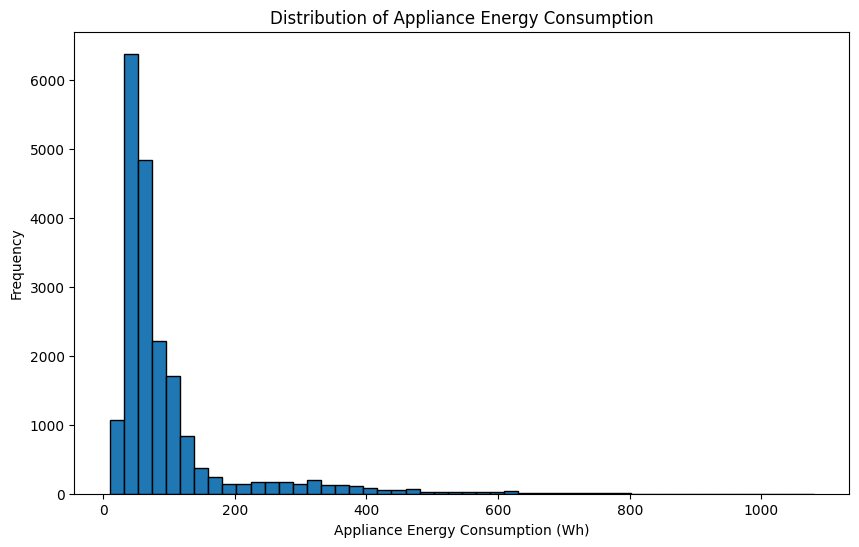

In [18]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["Appliances"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Appliance Energy Consumption (Wh)")
plt.ylabel("Frequency")
plt.title("Distribution of Appliance Energy Consumption")

plt.show()

In [19]:
target_skewness = df["Appliances"].skew()

print(
    "Target skewness:",
    round(target_skewness, 3)
)

Target skewness: 3.386


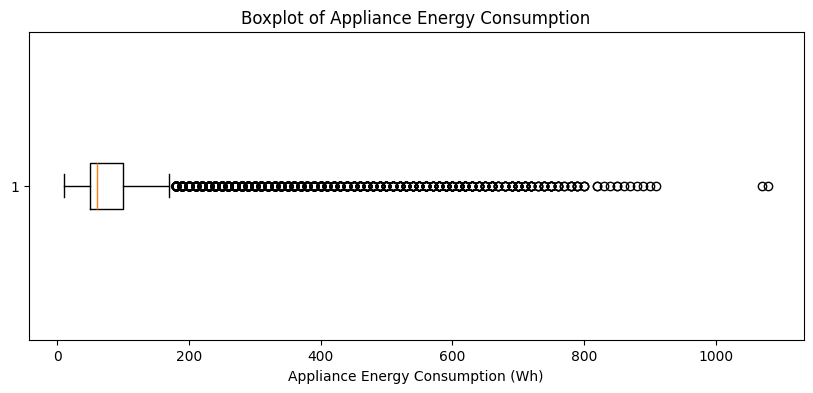

In [20]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df["Appliances"],
    vert=False
)

plt.xlabel("Appliance Energy Consumption (Wh)")
plt.title("Boxplot of Appliance Energy Consumption")

plt.show()

In [21]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower bound: -25.0
Upper bound: 175.0


In [22]:
target_outliers = df[
    (df["Appliances"] < lower_bound) |
    (df["Appliances"] > upper_bound)
]

print(
    "Number of IQR-flagged observations:",
    len(target_outliers)
)

print(
    "Percentage:",
    round(
        len(target_outliers) / len(df) * 100,
        2
    ),
    "%"
)

Number of IQR-flagged observations: 2138
Percentage: 10.83 %


In [23]:
df.nlargest(
    10,
    "Appliances"
)[
    ["date", "Appliances", "lights"]
]

,date,Appliances,lights
731,2016-01-16 18:50:00,1080,30
1451,2016-01-21 18:50:00,1070,30
432,2016-01-14 17:00:00,910,0
12088,2016-04-04 15:40:00,900,0
1452,2016-01-21 19:00:00,890,20
10668,2016-03-25 19:00:00,880,10
14693,2016-04-22 17:50:00,870,0
9031,2016-03-14 10:10:00,860,0
1821,2016-01-24 08:30:00,850,20
19582,2016-05-26 16:40:00,850,0


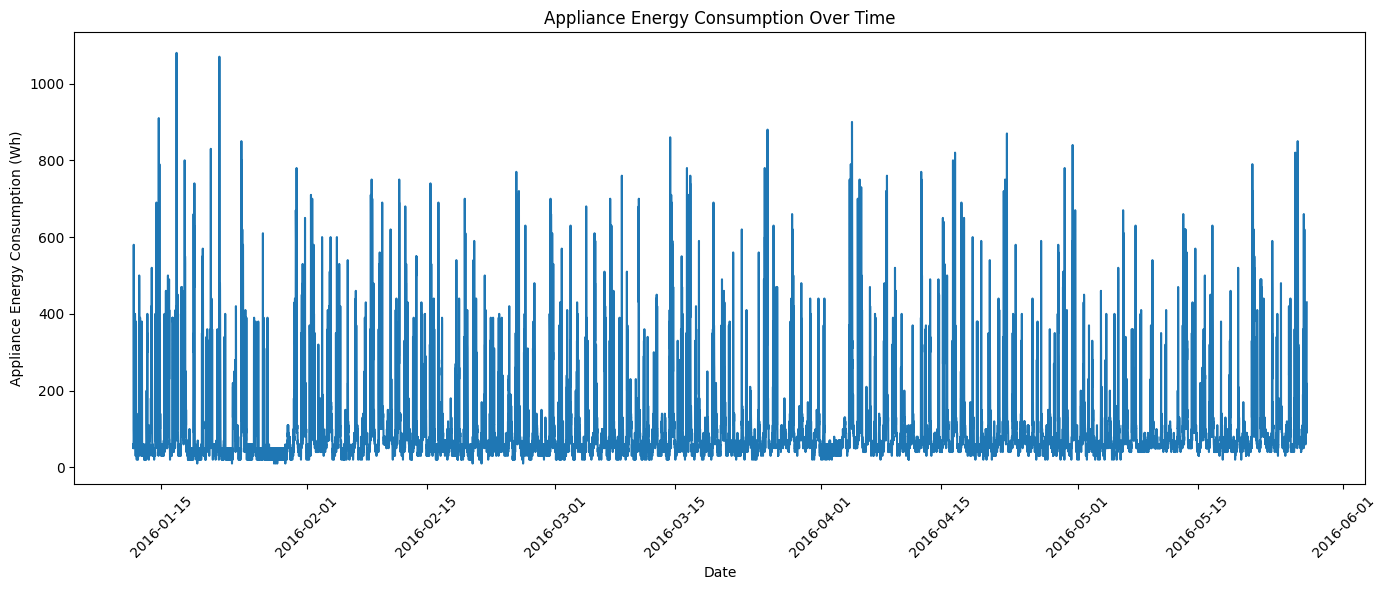

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["Appliances"]
)

plt.xlabel("Date")
plt.ylabel("Appliance Energy Consumption (Wh)")
plt.title("Appliance Energy Consumption Over Time")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [25]:
daily_energy = (
    df.set_index("date")["Appliances"]
      .resample("D")
      .mean()
)

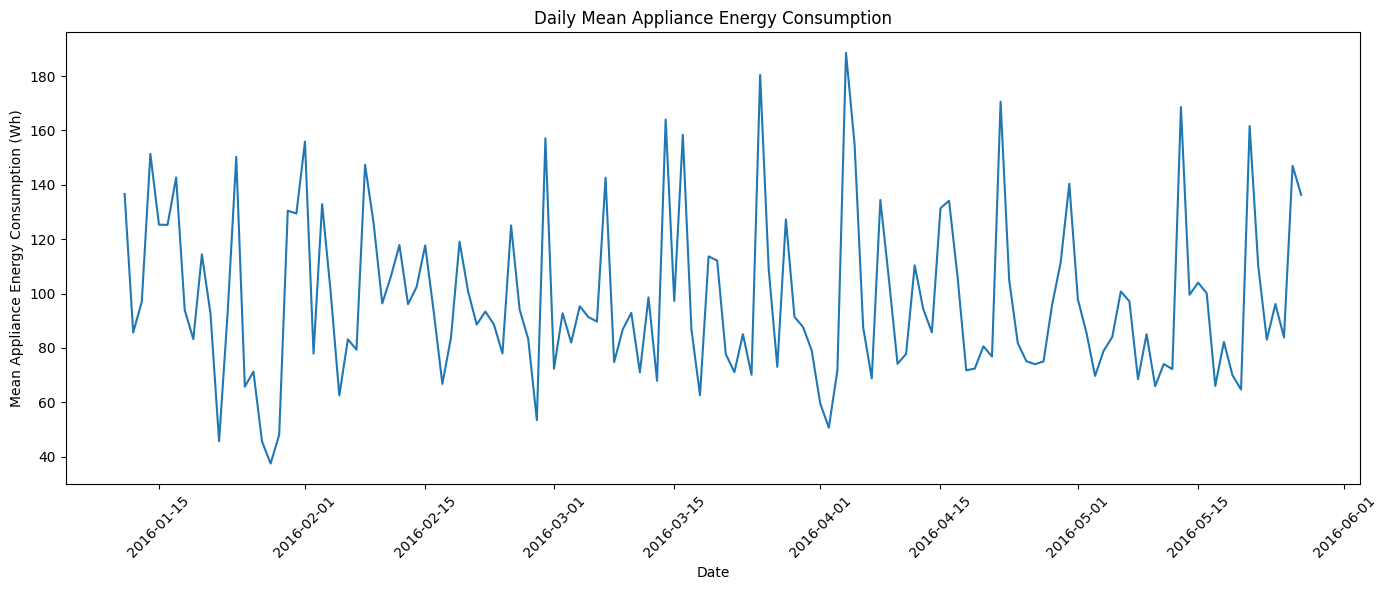

In [26]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_energy.index,
    daily_energy.values
)

plt.xlabel("Date")
plt.ylabel("Mean Appliance Energy Consumption (Wh)")
plt.title("Daily Mean Appliance Energy Consumption")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
df["hour"] = df["date"].dt.hour
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

In [28]:
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [29]:
hourly_energy = (
    df.groupby("hour")["Appliances"]
      .mean()
)

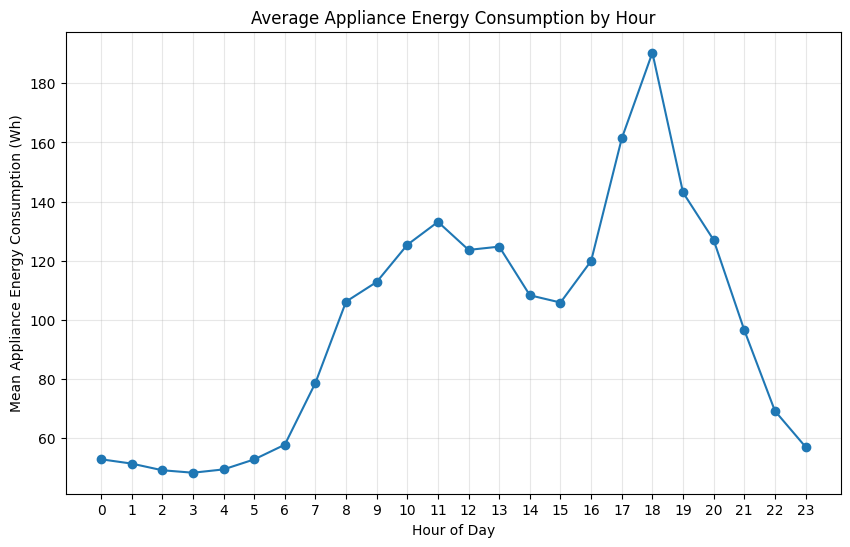

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(
    hourly_energy.index,
    hourly_energy.values,
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Mean Appliance Energy Consumption (Wh)")
plt.title("Average Appliance Energy Consumption by Hour")

plt.xticks(range(0, 24))

plt.grid(alpha=0.3)

plt.show()

In [31]:
weekday_energy = (
    df.groupby("day_of_week")["Appliances"]
      .mean()
)

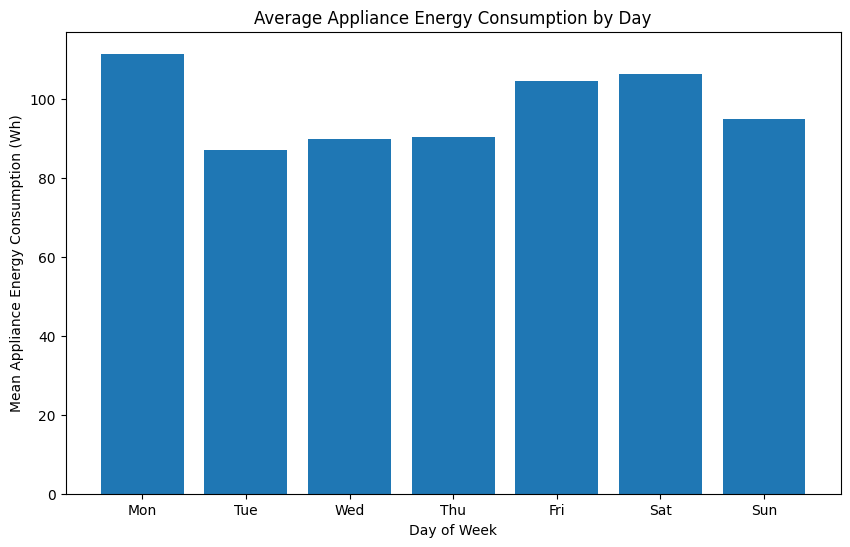

In [32]:
day_labels = [
    "Mon",
    "Tue",
    "Wed",
    "Thu",
    "Fri",
    "Sat",
    "Sun"
]

plt.figure(figsize=(10, 6))

plt.bar(
    day_labels,
    weekday_energy.values
)

plt.xlabel("Day of Week")
plt.ylabel("Mean Appliance Energy Consumption (Wh)")
plt.title("Average Appliance Energy Consumption by Day")

plt.show()

In [33]:
df.groupby(
    "is_weekend"
)["Appliances"].agg(
    ["mean", "median", "std"]
)

,mean,median,std
is_weekend,,,
0,96.587674,60.0,103.086372
1,100.581140,70.0,100.998987


### Key Findings: Target and Temporal Patterns

Appliance energy consumption is strongly right-skewed (skewness = 3.386),
with most observations concentrated at relatively low consumption levels and
a smaller number of high-demand periods.

Using the 1.5 × IQR criterion, 2,138 observations (10.83%) were flagged as
potential outliers. These observations were not automatically removed because
high energy-demand periods may represent legitimate household activity rather
than measurement error.

A clear time-of-day pattern was observed. Consumption was lowest during the
overnight and early-morning hours, increased during the morning, and reached
its highest average level around 18:00. Several of the largest individual
consumption observations also occurred during the late-afternoon and evening
period.

Mean consumption also varied across days of the week, with Monday showing the
highest average consumption and Tuesday the lowest within the observed study
period.

These findings suggest that temporal information contains potentially useful
predictive signal and should be considered during feature engineering.

In [34]:
numeric_df = df.select_dtypes(include=np.number)

target_corr = (
    numeric_df
    .corr()["Appliances"]
    .sort_values(ascending=False)
)

target_corr

Appliances     1.000000
hour           0.216792
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099154
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
is_weekend     0.017437
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
day_of_week    0.003060
Visibility     0.000230
rv2           -0.011145
rv1           -0.011145
month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64

In [35]:
target_corr = (
    numeric_df
    .corr()["Appliances"]
    .drop("Appliances")
    .sort_values()
)

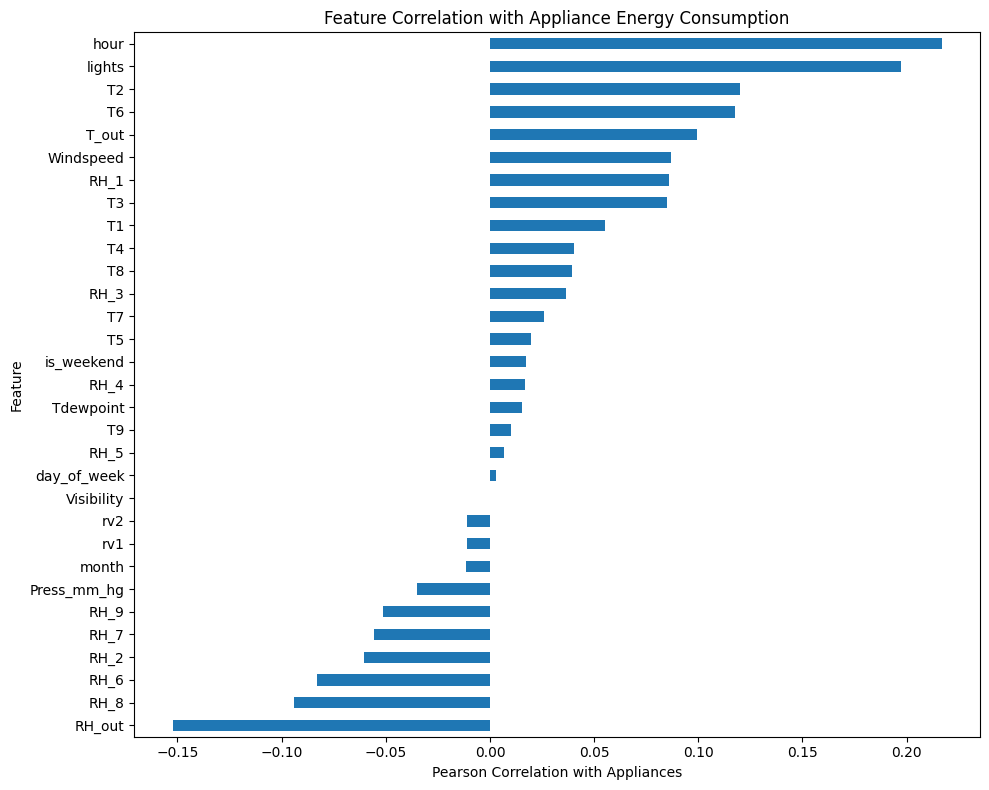

In [36]:
plt.figure(figsize=(10, 8))

target_corr.plot(kind="barh")

plt.xlabel("Pearson Correlation with Appliances")
plt.ylabel("Feature")
plt.title("Feature Correlation with Appliance Energy Consumption")

plt.tight_layout()
plt.show()

In [37]:
corr_matrix = numeric_df.corr()

In [38]:
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

high_corr_pairs.head(20)

rv1   rv2      1.000000
T6    T_out    0.974787
T7    T9       0.944776
T5    T9       0.911055
T3    T9       0.901324
RH_3  RH_4     0.898978
RH_4  RH_7     0.894301
T1    T3       0.892402
T9    month    0.890605
T4    T9       0.889439
T3    T5       0.888169
T1    T5       0.885247
RH_7  RH_8     0.883984
T7    T8       0.882123
RH_1  RH_4     0.880359
T4    T7       0.877763
T1    T4       0.877001
T4    T5       0.871813
T5    T7       0.870624
T8    T9       0.869338
dtype: float64

### Predictor Correlation and Multicollinearity

The predictor correlation analysis revealed substantial multicollinearity
among the environmental sensor variables. The strongest relationship was
between the two random variables (`rv1` and `rv2`), which were perfectly
correlated.

Strong correlations were also observed among temperature measurements.
For example, `T6` and outdoor temperature (`T_out`) had a correlation of
approximately 0.975, while several indoor temperature sensors exhibited
correlations above 0.85.

Similar relationships were observed among relative-humidity sensors,
indicating that multicollinearity is a structural characteristic of the
sensor data rather than an isolated feature pair.

These findings provide motivation for evaluating regularized linear models.
Ridge regression may improve coefficient stability in the presence of
correlated predictors, while Lasso and Elastic Net will allow investigation
of whether a smaller subset of predictors can retain useful predictive
information.

A strong relationship was also observed between `T9` and month, which may
reflect seasonal temperature changes across the January-to-May observation
period.

In [39]:
target_corr = (
    numeric_df
    .corr()["Appliances"]
    .drop("Appliances")
    .sort_values(ascending=False)
)

target_corr

hour           0.216792
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099154
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
is_weekend     0.017437
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
day_of_week    0.003060
Visibility     0.000230
rv2           -0.011145
rv1           -0.011145
month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64

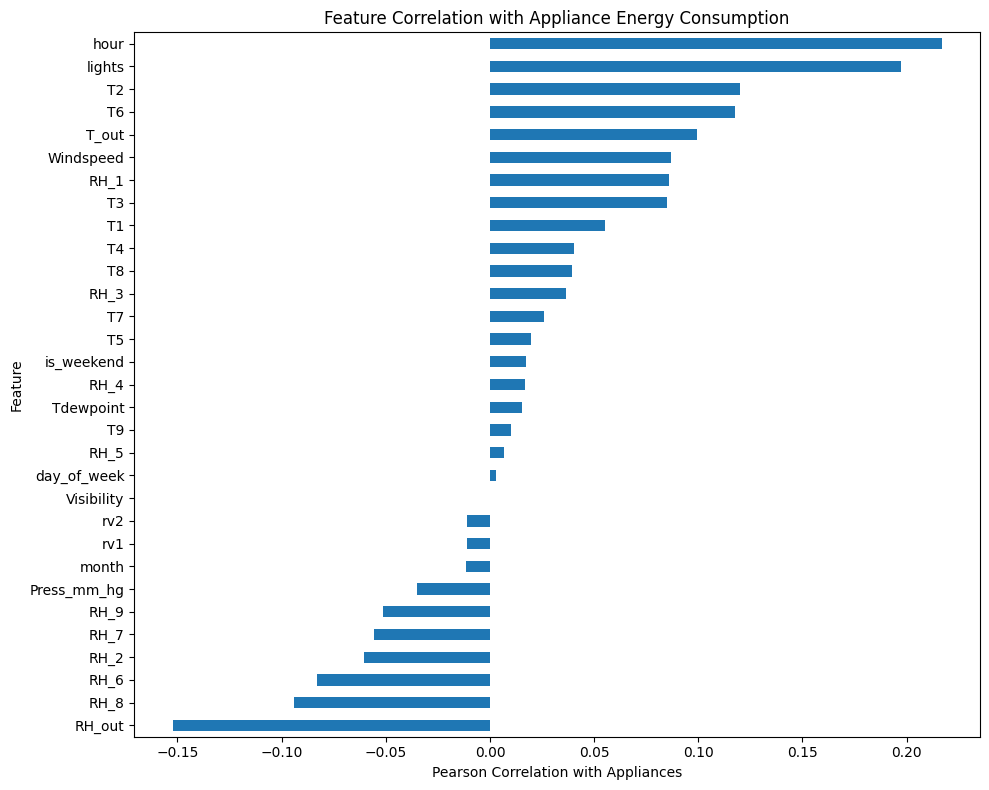

In [40]:
plt.figure(figsize=(10, 8))

target_corr.sort_values().plot(kind="barh")

plt.xlabel("Pearson Correlation with Appliances")
plt.ylabel("Feature")
plt.title("Feature Correlation with Appliance Energy Consumption")

plt.tight_layout()
plt.show()

In [41]:
print("Strongest positive correlations:")
print(target_corr.head(10))

print("\nStrongest negative correlations:")
print(target_corr.tail(10))

Strongest positive correlations:
hour         0.216792
lights       0.197278
T2           0.120073
T6           0.117638
T_out        0.099154
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
T1           0.055447
T4           0.040281
Name: Appliances, dtype: float64

Strongest negative correlations:
rv2           -0.011145
rv1           -0.011145
month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64


In [42]:
# Basic temporal features
df["hour"] = df["date"].dt.hour
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Cyclical hour encoding
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

# Cyclical day-of-week encoding
df["dow_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)

df["dow_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

In [43]:
df[
    [
        "date",
        "hour",
        "hour_sin",
        "hour_cos",
        "day_of_week",
        "dow_sin",
        "dow_cos",
        "month",
        "is_weekend"
    ]
].head(10)

,date,hour,hour_sin,hour_cos,day_of_week,dow_sin,dow_cos,month,is_weekend
0,2016-01-11 17:00:00,17,-0.965926,-2.588190e-01,0,0.0,1.0,1,0
1,2016-01-11 17:10:00,17,-0.965926,-2.588190e-01,0,0.0,1.0,1,0
2,2016-01-11 17:20:00,17,-0.965926,-2.588190e-01,0,0.0,1.0,1,0
3,2016-01-11 17:30:00,17,-0.965926,-2.588190e-01,0,0.0,1.0,1,0
4,2016-01-11 17:40:00,17,-0.965926,-2.588190e-01,0,0.0,1.0,1,0
5,2016-01-11 17:50:00,17,-0.965926,-2.588190e-01,0,0.0,1.0,1,0
6,2016-01-11 18:00:00,18,-1.000000,-1.836970e-16,0,0.0,1.0,1,0
7,2016-01-11 18:10:00,18,-1.000000,-1.836970e-16,0,0.0,1.0,1,0
8,2016-01-11 18:20:00,18,-1.000000,-1.836970e-16,0,0.0,1.0,1,0
9,2016-01-11 18:30:00,18,-1.000000,-1.836970e-16,0,0.0,1.0,1,0


### Temporal Feature Engineering

Exploratory analysis revealed substantial variation in appliance energy
consumption across hours of the day and days of the week. Temporal features
were therefore derived from the timestamp.

Hour and day-of-week are cyclical variables. Rather than representing them
only as integers, sine and cosine transformations were created so that
adjacent periods across cycle boundaries (for example, 23:00 and 00:00)
remain close in the feature space.

A weekend indicator and month variable were also retained. Because the
dataset covers only January through May, month is interpreted cautiously
and is not assumed to represent a complete annual seasonal cycle.

The raw timestamp will not be supplied directly to the regression models.

In [44]:
df["date"].is_monotonic_increasing

True

In [45]:
drop_columns = [
    "date",
    "Appliances",
    "hour",
    "day_of_week"
]

In [46]:
X = df.drop(columns=drop_columns)

y = df["Appliances"]

In [47]:
X.shape

(19735, 33)

In [48]:
X.columns.tolist()

['lights',
 'T1',
 'RH_1',
 'T2',
 'RH_2',
 'T3',
 'RH_3',
 'T4',
 'RH_4',
 'T5',
 'RH_5',
 'T6',
 'RH_6',
 'T7',
 'RH_7',
 'T8',
 'RH_8',
 'T9',
 'RH_9',
 'T_out',
 'Press_mm_hg',
 'RH_out',
 'Windspeed',
 'Visibility',
 'Tdewpoint',
 'rv1',
 'rv2',
 'month',
 'is_weekend',
 'hour_sin',
 'hour_cos',
 'dow_sin',
 'dow_cos']

In [49]:
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

In [50]:
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

In [51]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (13814, 33)
Validation: (2960, 33)
Test: (2961, 33)


In [52]:
print(
    "Train:",
    df.loc[:train_end - 1, "date"].min(),
    "to",
    df.loc[:train_end - 1, "date"].max()
)

print(
    "Validation:",
    df.loc[train_end:val_end - 1, "date"].min(),
    "to",
    df.loc[train_end:val_end - 1, "date"].max()
)

print(
    "Test:",
    df.loc[val_end:, "date"].min(),
    "to",
    df.loc[val_end:, "date"].max()
)

Train: 2016-01-11 17:00:00 to 2016-04-16 15:10:00
Validation: 2016-04-16 15:20:00 to 2016-05-07 04:30:00
Test: 2016-05-07 04:40:00 to 2016-05-27 18:00:00


In [53]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

## Validation Strategy and Leakage Prevention

Because the dataset consists of observations collected sequentially at
10-minute intervals, temporal ordering was preserved during model
evaluation. Rather than randomly distributing observations across training
and test sets, the data were divided chronologically into training,
validation, and final test periods.

This design provides a more conservative assessment of model generalization
to later observations and prevents future observations from directly
influencing model fitting.

Preprocessing transformations will be fitted using training data only and
subsequently applied to validation and test observations. Time-aware
cross-validation will also be used during hyperparameter tuning.

The initial modeling task is treated as concurrent energy estimation using
sensor and environmental measurements observed at the prediction timestamp.
A true future-forecasting system would require additional feature-availability
constraints, such as lagged sensor measurements or weather forecasts, and is
considered a potential extension.

In [56]:
train_mean = y_train.mean()

print("Training target mean:", train_mean)

Training target mean: 98.7751556392066


In [57]:
y_val_baseline = np.full(
    len(y_val),
    train_mean
)

In [58]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [59]:
baseline_mae = mean_absolute_error(
    y_val,
    y_val_baseline
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_baseline
    )
)

baseline_r2 = r2_score(
    y_val,
    y_val_baseline
)

In [60]:
print(f"Baseline MAE:  {baseline_mae:.2f} Wh")
print(f"Baseline RMSE: {baseline_rmse:.2f} Wh")
print(f"Baseline R²:   {baseline_r2:.3f}")

Baseline MAE:  53.97 Wh
Baseline RMSE: 92.39 Wh
Baseline R²:   -0.003


In [61]:
target_split_summary = pd.DataFrame({
    "Train": y_train.describe(),
    "Validation": y_val.describe(),
    "Test": y_test.describe()
})

target_split_summary

,Train,Validation,Test
count,13814.000000,2960.000000,2961.000000
mean,98.775156,93.422297,96.926714
std,106.857292,92.254684,90.888693
min,10.000000,20.000000,20.000000
25%,50.000000,50.000000,50.000000
50%,60.000000,60.000000,60.000000
75%,100.000000,100.000000,100.000000
max,1080.000000,870.000000,850.000000


In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [63]:
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [64]:
linear_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['lights','T1','RH_1',...,'hour_cos','dow_sin','dow_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [65]:
y_val_pred_linear = linear_pipeline.predict(
    X_val
)

In [66]:
linear_mae = mean_absolute_error(
    y_val,
    y_val_pred_linear
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred_linear
    )
)

linear_r2 = r2_score(
    y_val,
    y_val_pred_linear
)

In [67]:
print(f"Linear Regression MAE:  {linear_mae:.2f} Wh")
print(f"Linear Regression RMSE: {linear_rmse:.2f} Wh")
print(f"Linear Regression R²:   {linear_r2:.3f}")

Linear Regression MAE:  51.20 Wh
Linear Regression RMSE: 86.12 Wh
Linear Regression R²:   0.128


In [68]:
results = pd.DataFrame({
    "Model": [
        "Naive Mean Baseline",
        "Linear Regression"
    ],
    "MAE": [
        baseline_mae,
        linear_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Naive Mean Baseline,53.967763,92.394288,-0.003368
1,Linear Regression,51.197162,86.117044,0.128338


In [69]:
rmse_improvement = (
    (baseline_rmse - linear_rmse)
    / baseline_rmse
    * 100
)

print(
    f"RMSE improvement over baseline: "
    f"{rmse_improvement:.2f}%"
)

RMSE improvement over baseline: 6.79%


In [70]:
mae_improvement = (
    (baseline_mae - linear_mae)
    / baseline_mae
    * 100
)

print(
    f"MAE improvement over baseline: "
    f"{mae_improvement:.2f}%"
)

MAE improvement over baseline: 5.13%


### Baseline and Linear Regression Performance

The naive mean baseline produced an MAE of 53.97 Wh and an RMSE of
92.39 Wh, with an R² close to zero (-0.003), indicating that a constant
mean prediction provides essentially no explanatory value for the
validation-period energy consumption.

Linear Regression improved on the baseline, reducing MAE by approximately
5.1% and RMSE by approximately 6.8%. The model achieved an R² of 0.128,
indicating that approximately 12.8% of the variation in appliance energy
consumption was explained during the validation period.

Although Linear Regression provides measurable improvement over the naive
baseline, overall performance remains modest. The substantially larger RMSE
relative to MAE suggests that the model makes some large prediction errors,
likely during high-demand periods. Further residual analysis is therefore
needed before evaluating regularized alternatives.

In [71]:
linear_residuals = y_val - y_val_pred_linear

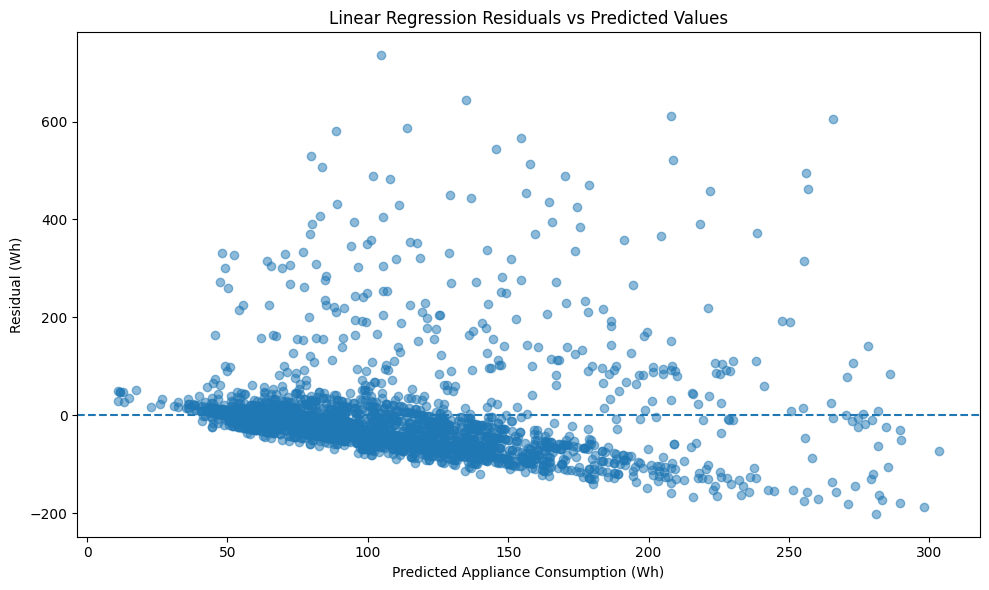

In [72]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_val_pred_linear,
    linear_residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Appliance Consumption (Wh)")
plt.ylabel("Residual (Wh)")
plt.title("Linear Regression Residuals vs Predicted Values")

plt.tight_layout()
plt.show()

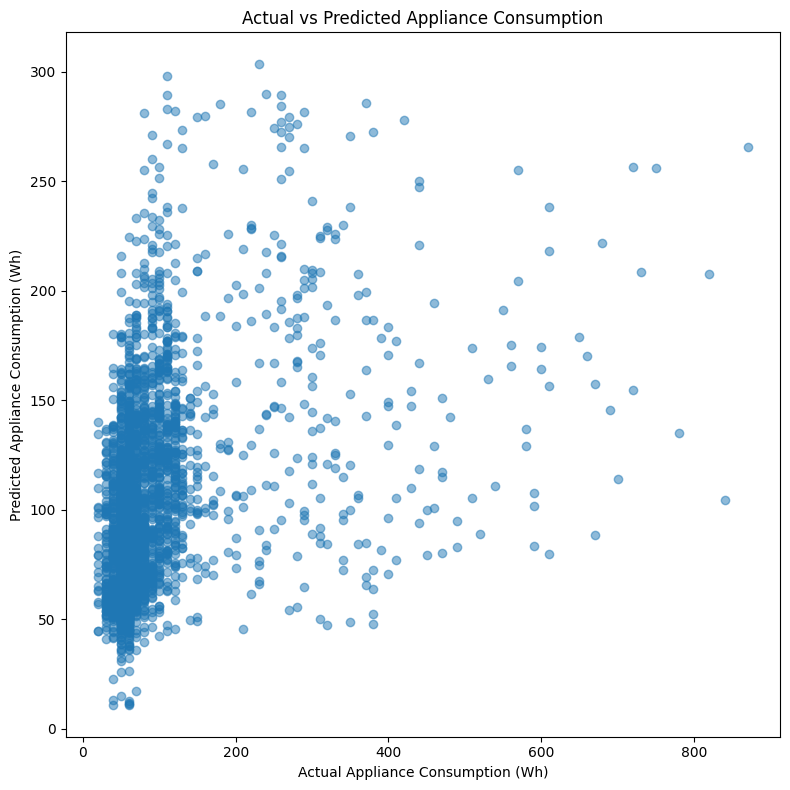

In [73]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_val,
    y_val_pred_linear,
    alpha=0.5
)

plt.xlabel("Actual Appliance Consumption (Wh)")
plt.ylabel("Predicted Appliance Consumption (Wh)")
plt.title("Actual vs Predicted Appliance Consumption")

plt.tight_layout()
plt.show()

In [74]:
error_analysis = pd.DataFrame({
    "Actual": y_val,
    "Predicted": y_val_pred_linear,
    "Residual": linear_residuals
})

error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
).head(20)

,Actual,Predicted,Residual,Absolute_Error
15798,840,104.644304,735.355696,735.355696
15664,780,135.065071,644.934929,644.934929
13821,820,207.850504,612.149496,612.149496
14693,870,265.729553,604.270447,604.270447
15799,700,114.083282,585.916718,585.916718
16647,670,88.587467,581.412533,581.412533
14640,720,154.585567,565.414433,565.414433
13928,690,145.556265,544.443735,544.443735
16659,610,79.751827,530.248173,530.248173
13820,730,208.602566,521.397434,521.397434


In [75]:
high_demand_mask = y_val >= 200

normal_mae = mean_absolute_error(
    y_val[~high_demand_mask],
    y_val_pred_linear[~high_demand_mask]
)

high_demand_mae = mean_absolute_error(
    y_val[high_demand_mask],
    y_val_pred_linear[high_demand_mask]
)

print(f"MAE below 200 Wh: {normal_mae:.2f} Wh")
print(f"MAE at or above 200 Wh: {high_demand_mae:.2f} Wh")

MAE below 200 Wh: 37.66 Wh
MAE at or above 200 Wh: 205.99 Wh


In [76]:
print(
    "High-demand observations:",
    high_demand_mask.sum()
)

print(
    "High-demand percentage:",
    round(high_demand_mask.mean() * 100, 2),
    "%"
)

High-demand observations: 238
High-demand percentage: 8.04 %


### Linear Regression Error Analysis

Residual analysis revealed that Linear Regression does not perform uniformly
across consumption levels. The largest errors were associated with
high-demand observations, where the model substantially underpredicted
actual appliance consumption.

For example, an observed consumption value of 840 Wh was predicted at
approximately 105 Wh, resulting in an error of approximately 735 Wh.
Several other high-demand observations produced errors greater than 500 Wh.

The residual-versus-predicted plot also exhibited systematic structure rather
than a completely random distribution around zero, suggesting that important
patterns in appliance demand are not adequately captured by the linear
specification.

This behavior helps explain the difference between MAE and RMSE. Because
RMSE penalizes large errors more heavily, severe underprediction during
high-demand periods disproportionately increases RMSE.

These results motivate further investigation of regularized linear models
for coefficient stability and, later, nonlinear models for potentially
capturing more complex relationships.

In [77]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [78]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

In [79]:
ridge_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['lights','T1','RH_1',...,'hour_cos','dow_sin','dow_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [80]:
y_val_pred_ridge = ridge_pipeline.predict(X_val)

In [81]:
ridge_mae = mean_absolute_error(
    y_val,
    y_val_pred_ridge
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred_ridge
    )
)

ridge_r2 = r2_score(
    y_val,
    y_val_pred_ridge
)

print(f"Ridge MAE:  {ridge_mae:.2f} Wh")
print(f"Ridge RMSE: {ridge_rmse:.2f} Wh")
print(f"Ridge R²:   {ridge_r2:.3f}")

Ridge MAE:  51.13 Wh
Ridge RMSE: 86.05 Wh
Ridge R²:   0.130


In [82]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Ridge (alpha=1)"
    ],

    "MAE": [
        baseline_mae,
        linear_mae,
        ridge_mae
    ],

    "RMSE": [
        baseline_rmse,
        linear_rmse,
        ridge_rmse
    ],

    "R2": [
        baseline_r2,
        linear_r2,
        ridge_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Naive Baseline,53.967763,92.394288,-0.003368
1,Linear Regression,51.197162,86.117044,0.128338
2,Ridge (alpha=1),51.131833,86.053384,0.129626


In [83]:
import numpy as np

ridge_alphas = np.logspace(
    -4,
    4,
    50
)

In [84]:
from sklearn.model_selection import GridSearchCV

In [85]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

In [86]:
ridge_grid = {
    "model__alpha": ridge_alphas
}

In [87]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

In [88]:
ridge_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'model__alpha': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defau

In [89]:
print(
    "Best Ridge alpha:",
    ridge_search.best_params_["model__alpha"]
)

Best Ridge alpha: 1526.4179671752302


In [90]:
print(
    "Best CV RMSE:",
    -ridge_search.best_score_
)

Best CV RMSE: 95.65708516450935


In [91]:
best_ridge = ridge_search.best_estimator_

In [92]:
y_val_pred_ridge_tuned = best_ridge.predict(
    X_val
)

In [93]:
ridge_tuned_mae = mean_absolute_error(
    y_val,
    y_val_pred_ridge_tuned
)

ridge_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred_ridge_tuned
    )
)

ridge_tuned_r2 = r2_score(
    y_val,
    y_val_pred_ridge_tuned
)

print(f"Tuned Ridge MAE:  {ridge_tuned_mae:.2f} Wh")
print(f"Tuned Ridge RMSE: {ridge_tuned_rmse:.2f} Wh")
print(f"Tuned Ridge R²:   {ridge_tuned_r2:.3f}")

Tuned Ridge MAE:  47.27 Wh
Tuned Ridge RMSE: 85.07 Wh
Tuned Ridge R²:   0.149


In [94]:
ridge_coefficients = pd.Series(
    best_ridge.named_steps["model"].coef_,
    index=X_train.columns
)

In [95]:
ridge_coefficients.sort_values(
    key=abs,
    ascending=False
)

hour_cos      -22.924375
T3             22.149200
lights         16.370679
RH_1           15.603448
hour_sin      -15.293689
RH_3           13.683436
T8              8.323254
RH_2           -8.244571
dow_sin        -7.666701
T9             -7.408204
RH_7           -6.632399
RH_8           -6.602855
RH_4           -5.803930
RH_9           -4.421716
is_weekend     -4.313198
T1             -3.898888
RH_out          3.493790
T4             -2.982093
dow_cos         2.805587
Windspeed       2.485752
T_out          -2.464056
RH_6           -2.310733
T6             -2.154931
month          -2.063961
T5             -1.941773
T2             -1.717476
Visibility      1.538704
T7             -0.579073
RH_5            0.570148
Press_mm_hg     0.399496
rv1            -0.282167
rv2            -0.282167
Tdewpoint      -0.074830
dtype: float64

In [96]:
linear_coefficients = pd.Series(
    linear_pipeline.named_steps["model"].coef_,
    index=X_train.columns
)

In [97]:
coefficient_comparison = pd.DataFrame({
    "Linear Regression": linear_coefficients,
    "Ridge": ridge_coefficients
})

coefficient_comparison["Linear_abs"] = (
    coefficient_comparison["Linear Regression"].abs()
)

coefficient_comparison["Ridge_abs"] = (
    coefficient_comparison["Ridge"].abs()
)

In [98]:
coefficient_comparison.sort_values(
    "Linear_abs",
    ascending=False
).head(20)

,Linear Regression,Ridge,Linear_abs,Ridge_abs
Tdewpoint,40.017958,-0.074830,40.017958,0.074830
T3,38.681887,22.149200,38.681887,22.149200
RH_2,-35.556044,-8.244571,35.556044,8.244571
RH_3,33.700671,13.683436,33.700671,13.683436
RH_1,33.234136,15.603448,33.234136,15.603448
T_out,-31.709630,-2.464056,31.709630,2.464056
hour_cos,-28.224219,-22.924375,28.224219,22.924375
T9,-25.593438,-7.408204,25.593438,7.408204
T2,-22.876839,-1.717476,22.876839,1.717476
lights,16.608123,16.370679,16.608123,16.370679


In [99]:
coefficient_comparison.loc[
    [
        "rv1",
        "rv2",
        "T6",
        "T_out",
        "T7",
        "T9"
    ]
]

,Linear Regression,Ridge,Linear_abs,Ridge_abs
rv1,-0.303438,-0.282167,0.303438,0.282167
rv2,-0.303438,-0.282167,0.303438,0.282167
T6,-8.912702,-2.154931,8.912702,2.154931
T_out,-31.709630,-2.464056,31.709630,2.464056
T7,3.743445,-0.579073,3.743445,0.579073
T9,-25.593438,-7.408204,25.593438,7.408204


### Ridge Regression

Ridge Regression was evaluated because exploratory analysis revealed
substantial multicollinearity among the environmental sensor variables.
The regularization parameter was tuned using time-aware cross-validation
within the training period.

The optimal Ridge penalty was approximately 1526.42. The tuned model
achieved an MAE of 47.27 Wh, RMSE of 85.07 Wh, and R² of 0.149 on the
chronologically held-out validation period.

Compared with ordinary Linear Regression, Ridge reduced MAE from 51.20 Wh
to 47.27 Wh and RMSE from 86.12 Wh to 85.07 Wh while increasing R² from
0.128 to 0.149. The larger improvement in MAE than RMSE suggests that
regularization improved typical prediction errors but did not fully resolve
the large errors associated with high-demand periods.

Overall, Ridge provided a modest improvement over ordinary Linear Regression,
supporting the value of regularization in this highly correlated feature
space. However, the remaining error indicates that coefficient shrinkage
alone is insufficient to capture the full structure of appliance energy
demand.

In [100]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=20000))
])

In [101]:
lasso_alphas = np.logspace(
    -4,
    2,
    60
)

In [102]:
lasso_grid = {
    "model__alpha": lasso_alphas
}

In [103]:
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

In [104]:
lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=20000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'model__alpha': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

In [105]:
print(
    "Best Lasso alpha:",
    lasso_search.best_params_["model__alpha"]
)

print(
    "Best CV RMSE:",
    -lasso_search.best_score_
)

Best Lasso alpha: 2.359833466782194
Best CV RMSE: 95.44590760427367


In [106]:
best_lasso = lasso_search.best_estimator_

y_val_pred_lasso = best_lasso.predict(X_val)

In [107]:
lasso_mae = mean_absolute_error(
    y_val,
    y_val_pred_lasso
)

lasso_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred_lasso
    )
)

lasso_r2 = r2_score(
    y_val,
    y_val_pred_lasso
)

print(f"Lasso MAE:  {lasso_mae:.2f} Wh")
print(f"Lasso RMSE: {lasso_rmse:.2f} Wh")
print(f"Lasso R²:   {lasso_r2:.3f}")

Lasso MAE:  48.14 Wh
Lasso RMSE: 85.84 Wh
Lasso R²:   0.134


In [108]:
lasso_coefficients = pd.Series(
    best_lasso.named_steps["model"].coef_,
    index=X_train.columns
)

In [109]:
n_zero = (lasso_coefficients == 0).sum()
n_nonzero = (lasso_coefficients != 0).sum()

print("Zero coefficients:", n_zero)
print("Selected features:", n_nonzero)
print("Total features:", len(lasso_coefficients))

Zero coefficients: 18
Selected features: 15
Total features: 33


In [110]:
lasso_coefficients[
    lasso_coefficients == 0
].index.tolist()

['T1',
 'T2',
 'RH_4',
 'T5',
 'RH_5',
 'RH_6',
 'T7',
 'T8',
 'RH_8',
 'RH_9',
 'Press_mm_hg',
 'RH_out',
 'Windspeed',
 'Visibility',
 'rv1',
 'rv2',
 'month',
 'is_weekend']

In [111]:
lasso_coefficients[
    lasso_coefficients != 0
].sort_values(
    key=abs,
    ascending=False
)

hour_cos    -23.742340
hour_sin    -19.072072
lights       16.825186
T3           14.871057
RH_7         -6.275756
RH_1          5.070315
T_out        -3.900367
RH_3          3.406960
dow_sin      -2.497520
T9           -2.432675
Tdewpoint    -0.923180
T4           -0.773440
T6           -0.681332
dow_cos       0.680200
RH_2         -0.363032
dtype: float64

In [112]:
lasso_coefficients[
    ["rv1", "rv2"]
]

rv1   -0.0
rv2   -0.0
dtype: float64

In [113]:
removed_features = lasso_coefficients[
    lasso_coefficients == 0
].index.tolist()

print("Features removed by Lasso:")

for feature in removed_features:
    print(feature)

Features removed by Lasso:
T1
T2
RH_4
T5
RH_5
RH_6
T7
T8
RH_8
RH_9
Press_mm_hg
RH_out
Windspeed
Visibility
rv1
rv2
month
is_weekend


In [114]:
selected_features = (
    lasso_coefficients[
        lasso_coefficients != 0
    ]
    .sort_values(
        key=abs,
        ascending=False
    )
)

selected_features

hour_cos    -23.742340
hour_sin    -19.072072
lights       16.825186
T3           14.871057
RH_7         -6.275756
RH_1          5.070315
T_out        -3.900367
RH_3          3.406960
dow_sin      -2.497520
T9           -2.432675
Tdewpoint    -0.923180
T4           -0.773440
T6           -0.681332
dow_cos       0.680200
RH_2         -0.363032
dtype: float64

### Lasso Regression

Lasso Regression was evaluated to determine whether L1 regularization could
reduce model complexity through automatic feature selection. The
regularization parameter was tuned using time-aware cross-validation, which
selected an alpha of approximately 2.36.

The tuned Lasso model achieved an MAE of 48.14 Wh, RMSE of 85.84 Wh, and
R² of 0.134 on the validation period. Although its predictive performance
was slightly weaker than Ridge Regression, Lasso produced a substantially
sparser model.

Of the 33 candidate predictors, 18 coefficients were reduced exactly to
zero, leaving 15 selected features. Notably, both deliberately random
variables (rv1 and rv2) received zero coefficients, demonstrating Lasso's
ability to suppress predictors that provide little incremental predictive
value.

These results illustrate a tradeoff between predictive performance and model
sparsity: Ridge achieved the strongest validation performance among the
linear models evaluated so far, whereas Lasso achieved substantial feature
reduction with only a modest loss in predictive accuracy.

In [115]:
from sklearn.linear_model import ElasticNet

elastic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(max_iter=50000))
])

In [116]:
elastic_alphas = np.logspace(
    -3,
    2,
    30
)

elastic_l1_ratios = [
    0.1,
    0.25,
    0.5,
    0.75,
    0.9,
    0.95
]

In [117]:
elastic_grid = {
    "model__alpha": elastic_alphas,
    "model__l1_ratio": elastic_l1_ratios
}

In [118]:
elastic_search = GridSearchCV(
    estimator=elastic_pipeline,
    param_grid=elastic_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

In [119]:
elastic_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=50000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': array([1.0000...00000000e+02]), 'model__l1_ratio': [0.1, 0.25, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added

In [120]:
print(
    "Best Elastic Net alpha:",
    elastic_search.best_params_["model__alpha"]
)

print(
    "Best Elastic Net l1_ratio:",
    elastic_search.best_params_["model__l1_ratio"]
)

print(
    "Best CV RMSE:",
    -elastic_search.best_score_
)

Best Elastic Net alpha: 1.2689610031679235
Best Elastic Net l1_ratio: 0.95
Best CV RMSE: 95.40557637443654


In [121]:
best_elastic = elastic_search.best_estimator_

y_val_pred_elastic = best_elastic.predict(
    X_val
)

In [122]:
elastic_mae = mean_absolute_error(
    y_val,
    y_val_pred_elastic
)

elastic_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred_elastic
    )
)

elastic_r2 = r2_score(
    y_val,
    y_val_pred_elastic
)

print(f"Elastic Net MAE:  {elastic_mae:.2f} Wh")
print(f"Elastic Net RMSE: {elastic_rmse:.2f} Wh")
print(f"Elastic Net R²:   {elastic_r2:.3f}")

Elastic Net MAE:  48.08 Wh
Elastic Net RMSE: 85.45 Wh
Elastic Net R²:   0.142


In [123]:
elastic_coefficients = pd.Series(
    best_elastic.named_steps["model"].coef_,
    index=X_train.columns
)

In [124]:
elastic_zero = (
    elastic_coefficients == 0
).sum()

elastic_nonzero = (
    elastic_coefficients != 0
).sum()

print("Zero coefficients:", elastic_zero)
print("Selected features:", elastic_nonzero)
print("Total features:", len(elastic_coefficients))

Zero coefficients: 10
Selected features: 23
Total features: 33


In [125]:
elastic_coefficients[
    elastic_coefficients == 0
].index.tolist()

['T2',
 'RH_5',
 'RH_6',
 'T7',
 'Press_mm_hg',
 'RH_out',
 'Tdewpoint',
 'rv1',
 'rv2',
 'month']

In [126]:
elastic_coefficients[
    ["rv1", "rv2"]
]

rv1   -0.0
rv2   -0.0
dtype: float64

In [127]:
linear_model_results = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],

    "MAE": [
        baseline_mae,
        linear_mae,
        ridge_tuned_mae,
        lasso_mae,
        elastic_mae
    ],

    "RMSE": [
        baseline_rmse,
        linear_rmse,
        ridge_tuned_rmse,
        lasso_rmse,
        elastic_rmse
    ],

    "R2": [
        baseline_r2,
        linear_r2,
        ridge_tuned_r2,
        lasso_r2,
        elastic_r2
    ]
})

linear_model_results.sort_values("RMSE")

,Model,MAE,RMSE,R2
2,Ridge,47.270564,85.073678,0.149332
4,Elastic Net,48.084490,85.452751,0.141734
3,Lasso,48.135861,85.841695,0.133903
1,Linear Regression,51.197162,86.117044,0.128338
0,Naive Baseline,53.967763,92.394288,-0.003368


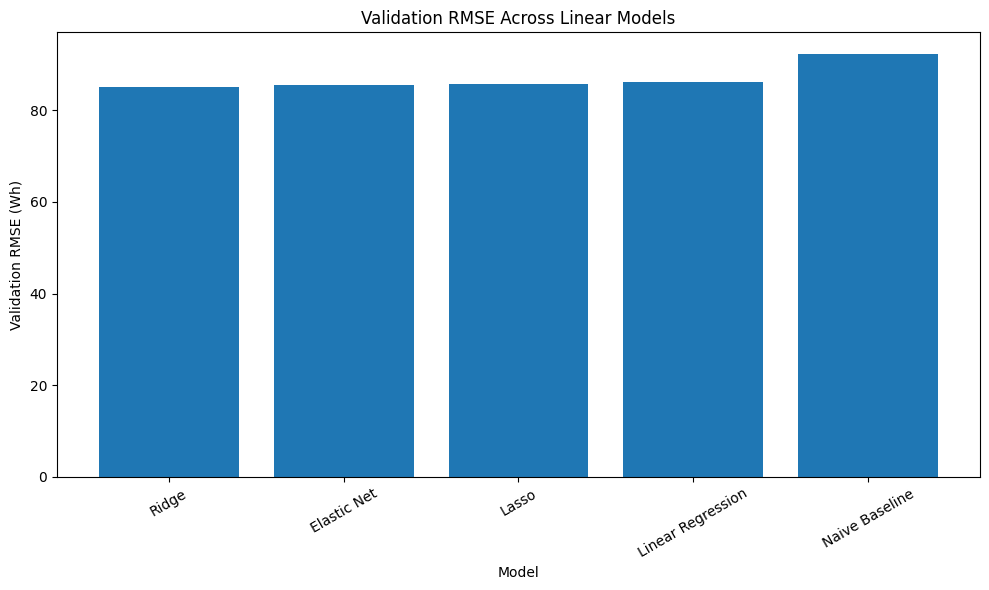

In [128]:
plot_results = (
    linear_model_results
    .sort_values("RMSE")
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_results["Model"],
    plot_results["RMSE"]
)

plt.ylabel("Validation RMSE (Wh)")
plt.xlabel("Model")
plt.title("Validation RMSE Across Linear Models")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Linear Model Comparison

Four linear modeling approaches were evaluated against a naive mean
baseline: ordinary Linear Regression, Ridge Regression, Lasso Regression,
and Elastic Net.

All linear models improved upon the naive baseline. Ridge Regression achieved
the strongest validation performance, with an MAE of 47.27 Wh, RMSE of
85.07 Wh, and R² of 0.149.

Regularization was particularly relevant because exploratory analysis
identified substantial multicollinearity among the environmental sensor
variables. Ridge substantially reduced the magnitude of several unstable
coefficients while retaining all predictors.

Lasso provided the strongest feature-selection effect, reducing 18 of 33
coefficients to zero and retaining only 15 predictors. Elastic Net produced
an intermediate solution, retaining 23 predictors. Both Lasso and Elastic
Net eliminated the deliberately random variables rv1 and rv2.

Although regularization improved coefficient behavior and produced modest
gains in predictive performance, residual analysis showed that the linear
models continued to substantially underpredict high-consumption events.
This suggests that regularization alone cannot address all of the structure
in appliance energy demand and motivates evaluation of nonlinear models.

## Decision Tree Regression

The linear and regularized regression models provided useful baselines but showed limited predictive performance, particularly for high-energy-consumption observations. This suggests that nonlinear relationships and interactions among the predictors may be important.

A Decision Tree Regressor is therefore evaluated as the first nonlinear model. Unlike linear regression, a decision tree recursively partitions the feature space and can capture nonlinear relationships and feature interactions without requiring them to be specified explicitly.

In [129]:
print(X_train.shape)
print(y_train.shape)

(13814, 33)
(13814,)


In [130]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    random_state=42
)

dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [131]:
dt_train_pred = dt.predict(X_train)
dt_val_pred = dt.predict(X_val)

In [132]:
dt_train_mae = mean_absolute_error(y_train, dt_train_pred)
dt_train_rmse = mean_squared_error(y_train, dt_train_pred) ** 0.5
dt_train_r2 = r2_score(y_train, dt_train_pred)

dt_val_mae = mean_absolute_error(y_val, dt_val_pred)
dt_val_rmse = mean_squared_error(y_val, dt_val_pred) ** 0.5
dt_val_r2 = r2_score(y_val, dt_val_pred)

print("Decision Tree - Training")
print(f"MAE:  {dt_train_mae:.2f}")
print(f"RMSE: {dt_train_rmse:.2f}")
print(f"R²:   {dt_train_r2:.3f}")

print("\nDecision Tree - Validation")
print(f"MAE:  {dt_val_mae:.2f}")
print(f"RMSE: {dt_val_rmse:.2f}")
print(f"R²:   {dt_val_r2:.3f}")

Decision Tree - Training
MAE:  0.00
RMSE: 0.00
R²:   1.000

Decision Tree - Validation
MAE:  63.69
RMSE: 123.89
R²:   -0.804


In [133]:
param_grid_dt = {
    "max_depth": [3, 5, 8, 12, 16, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10, 20]
}

In [134]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

dt_tuned = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_dt,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

dt_tuned.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callab

In [135]:
print("Best parameters:")
print(dt_tuned.best_params_)

print("\nBest CV RMSE:")
print(f"{-dt_tuned.best_score_:.2f}")

Best parameters:
{'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}

Best CV RMSE:
102.59


In [136]:
best_dt = dt_tuned.best_estimator_

dt_tuned_train_pred = best_dt.predict(X_train)
dt_tuned_val_pred = best_dt.predict(X_val)

print("Tuned Decision Tree - Training")
print(f"MAE:  {mean_absolute_error(y_train, dt_tuned_train_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_train, dt_tuned_train_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_train, dt_tuned_train_pred):.3f}")

print("\nTuned Decision Tree - Validation")
print(f"MAE:  {mean_absolute_error(y_val, dt_tuned_val_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_val, dt_tuned_val_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_val, dt_tuned_val_pred):.3f}")

Tuned Decision Tree - Training
MAE:  53.01
RMSE: 95.97
R²:   0.193

Tuned Decision Tree - Validation
MAE:  51.11
RMSE: 89.04
R²:   0.068


### Decision Tree Interpretation

Time-series cross-validation selected a relatively shallow Decision Tree (`max_depth=3`, `min_samples_leaf=2`, `min_samples_split=2`), with a cross-validation RMSE of 102.59.

The tuned model achieved a training RMSE of 95.97 (R² = 0.193) and a validation RMSE of 89.04 (R² = 0.068). The relatively modest gap between training and validation performance indicates that constraining tree depth reduced severe overfitting. However, the low training and validation R² values suggest that the shallow tree has relatively high bias and is unable to capture much of the variation in appliance energy consumption.

The tuned Decision Tree also did not outperform the strongest regularized linear model on the validation data. This motivates evaluating Random Forest, which combines multiple diversified Decision Trees to capture nonlinear relationships while reducing the variance associated with individual trees.

In [137]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [138]:
rf_train_pred = rf.predict(X_train)
rf_val_pred = rf.predict(X_val)

print("Random Forest - Training")
print(f"MAE:  {mean_absolute_error(y_train, rf_train_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_train, rf_train_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_train, rf_train_pred):.3f}")

print("\nRandom Forest - Validation")
print(f"MAE:  {mean_absolute_error(y_val, rf_val_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_val, rf_val_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_val, rf_val_pred):.3f}")

Random Forest - Training
MAE:  11.64
RMSE: 24.41
R²:   0.948

Random Forest - Validation
MAE:  71.04
RMSE: 105.72
R²:   -0.314


### Random Forest Baseline Interpretation

The baseline Random Forest achieved very strong training performance (RMSE = 24.41, R² = 0.948) but substantially worse validation performance (RMSE = 105.72, R² = -0.314).

The large training-validation performance gap indicates severe overfitting: the model captured the training observations extremely well but failed to generalize to the later validation period. The negative validation R² further indicates that the model performed poorly on unseen future observations.

Although Random Forest reduces the variance of individual Decision Trees through averaging, unrestricted trees can still produce an overly complex ensemble. Therefore, the next step is to regularize the forest by tuning tree depth, minimum leaf size, feature sampling, and related complexity controls using time-series cross-validation.

In [139]:
from sklearn.model_selection import RandomizedSearchCV

param_dist_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", 0.5, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_dist_rf,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [3, 5, ...], 'max_features': ['sqrt', 0.5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best es

In [140]:
print("Best parameters:")
print(rf_search.best_params_)

print("\nBest CV RMSE:")
print(f"{-rf_search.best_score_:.2f}")

Best parameters:
{'n_estimators': 500, 'min_samples_split': 20, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 5}

Best CV RMSE:
95.87


In [141]:
best_rf = rf_search.best_estimator_

rf_tuned_train_pred = best_rf.predict(X_train)
rf_tuned_val_pred = best_rf.predict(X_val)

print("Tuned Random Forest - Training")
print(f"MAE:  {mean_absolute_error(y_train, rf_tuned_train_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_train, rf_tuned_train_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_train, rf_tuned_train_pred):.3f}")

print("\nTuned Random Forest - Validation")
print(f"MAE:  {mean_absolute_error(y_val, rf_tuned_val_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_val, rf_tuned_val_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_val, rf_tuned_val_pred):.3f}")

Tuned Random Forest - Training
MAE:  48.22
RMSE: 88.38
R²:   0.316

Tuned Random Forest - Validation
MAE:  49.91
RMSE: 86.20
R²:   0.127


### Tuned Random Forest Interpretation

Hyperparameter tuning substantially improved the Random Forest's ability to generalize. The baseline forest severely overfit the training data (training R² = 0.948; validation R² = -0.314), whereas the tuned model produced much more comparable training and validation performance.

The tuned Random Forest achieved a training RMSE of 88.38 (R² = 0.316) and a validation RMSE of 86.20 (R² = 0.127). Although training performance decreased substantially after regularization, validation performance improved considerably, demonstrating the importance of controlling model complexity.

The tuned Random Forest was competitive with, but did not outperform, the strongest regularized linear model on the validation period. This motivates evaluating a boosting approach, where trees are constructed sequentially to improve the errors remaining from the current ensemble.

In [142]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    random_state=42
)

gbr.fit(X_train, y_train)

gbr_train_pred = gbr.predict(X_train)
gbr_val_pred = gbr.predict(X_val)

print("Gradient Boosting - Training")
print(f"MAE:  {mean_absolute_error(y_train, gbr_train_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_train, gbr_train_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_train, gbr_train_pred):.3f}")

print("\nGradient Boosting - Validation")
print(f"MAE:  {mean_absolute_error(y_val, gbr_val_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_val, gbr_val_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_val, gbr_val_pred):.3f}")

Gradient Boosting - Training
MAE:  44.14
RMSE: 80.75
R²:   0.429

Gradient Boosting - Validation
MAE:  64.04
RMSE: 107.27
R²:   -0.353


In [143]:
param_dist_gbr = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_samples_leaf": [5, 10, 20, 30],
    "subsample": [0.6, 0.8, 1.0]
}

gbr_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist_gbr,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gbr_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [5, 10, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best es

In [144]:
print("Best parameters:")
print(gbr_search.best_params_)

print("\nBest CV RMSE:")
print(f"{-gbr_search.best_score_:.2f}")

Best parameters:
{'subsample': 1.0, 'n_estimators': 100, 'min_samples_leaf': 30, 'max_depth': 3, 'learning_rate': 0.01}

Best CV RMSE:
97.36


In [145]:
best_gbr = gbr_search.best_estimator_

gbr_tuned_train_pred = best_gbr.predict(X_train)
gbr_tuned_val_pred = best_gbr.predict(X_val)

print("Tuned Gradient Boosting - Training")
print(f"MAE:  {mean_absolute_error(y_train, gbr_tuned_train_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_train, gbr_tuned_train_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_train, gbr_tuned_train_pred):.3f}")

print("\nTuned Gradient Boosting - Validation")
print(f"MAE:  {mean_absolute_error(y_val, gbr_tuned_val_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_val, gbr_tuned_val_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_val, gbr_tuned_val_pred):.3f}")

Tuned Gradient Boosting - Training
MAE:  54.40
RMSE: 96.03
R²:   0.192

Tuned Gradient Boosting - Validation
MAE:  48.07
RMSE: 84.87
R²:   0.153


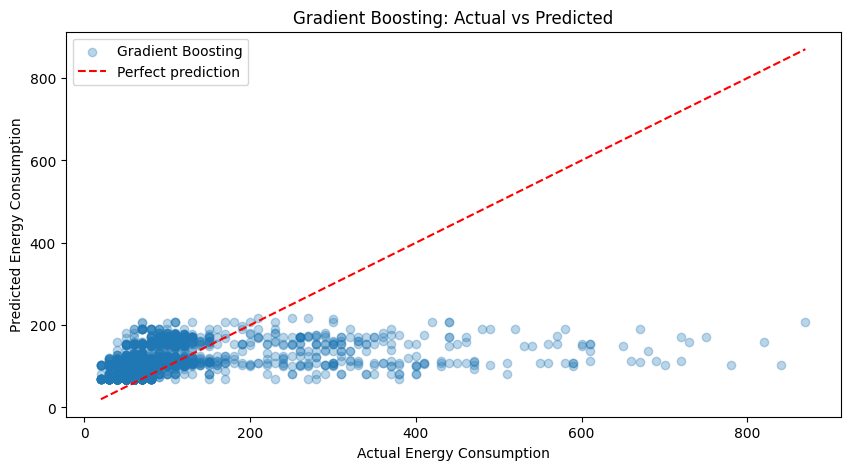

In [146]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    y_val,
    gbr_tuned_val_pred,
    alpha=0.3,
    label="Gradient Boosting"
)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.legend()
plt.show()

### Actual vs. Predicted Values

The actual-versus-predicted plot shows that the tuned Gradient Boosting model performs more effectively within the common range of appliance energy consumption but systematically underpredicts high-consumption observations.

As actual consumption increases, predictions remain concentrated within a substantially narrower range. This indicates that the model has difficulty capturing extreme energy-demand events. These large underprediction errors also contribute disproportionately to RMSE.

Therefore, although Gradient Boosting achieved the strongest validation performance among the evaluated models, important predictive limitations remain, particularly during periods of unusually high appliance energy consumption.

In [147]:
import pandas as pd

error_analysis = pd.DataFrame({
    "actual": y_val,
    "predicted": gbr_tuned_val_pred
})

error_analysis["residual"] = (
    error_analysis["actual"] - error_analysis["predicted"]
)

error_analysis["absolute_error"] = (
    error_analysis["residual"].abs()
)

error_analysis.sort_values(
    "absolute_error",
    ascending=False
).head(10)

,actual,predicted,residual,absolute_error
15798,840,103.287475,736.712525,736.712525
15664,780,103.287475,676.712525,676.712525
14693,870,208.025834,661.974166,661.974166
13821,820,159.150650,660.849350,660.849350
14640,720,113.845096,606.154904,606.154904
15799,700,103.287475,596.712525,596.712525
14662,750,171.361098,578.638902,578.638902
13928,690,113.845096,576.154904,576.154904
13820,730,159.150650,570.849350,570.849350
16647,670,109.282505,560.717495,560.717495


### Analysis of Largest Prediction Errors

Inspection of the ten largest absolute errors confirms the pattern observed in the actual-versus-predicted plot. The model's largest errors occur during high-consumption observations, with actual appliance energy consumption ranging approximately from 670 to 870 Wh.

All ten cases have large positive residuals, indicating substantial underprediction. For example, an actual consumption value of 840 Wh was predicted as approximately 103 Wh, producing an error of about 737 Wh.

These results indicate that the model performs substantially worse during extreme energy-consumption events than during typical consumption periods. The relatively small number of high-consumption observations and the strongly right-skewed target distribution may contribute to this behavior.

In [148]:
error_analysis["consumption_group"] = pd.cut(
    error_analysis["actual"],
    bins=[0, 100, 200, 400, float("inf")],
    labels=["0-100", "101-200", "201-400", ">400"]
)

error_by_group = (
    error_analysis
    .groupby("consumption_group", observed=True)
    .agg(
        observations=("actual", "size"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean")
    )
)

error_by_group

,observations,MAE,mean_residual
consumption_group,,,
0-100,2370,33.521900,-33.174270
101-200,360,28.444006,-3.271379
201-400,168,158.550248,158.457604
>400,62,418.548982,418.548982


### Error Across Consumption Levels

Prediction performance varied substantially across consumption levels. For observations between 0 and 100 Wh, the model had an MAE of 33.52 Wh and tended to overpredict consumption. Performance was strongest between 101 and 200 Wh, where MAE was 28.44 Wh and the mean residual was close to zero.

However, prediction error increased sharply for high-consumption observations. For values between 201 and 400 Wh, MAE increased to 158.55 Wh, with a mean residual of +158.46 Wh. For observations above 400 Wh, MAE reached 418.55 Wh, and the mean residual was +418.55 Wh.

This confirms that the model systematically underpredicts high-consumption events. Therefore, the overall validation metrics conceal substantial variation in predictive performance across different consumption levels.

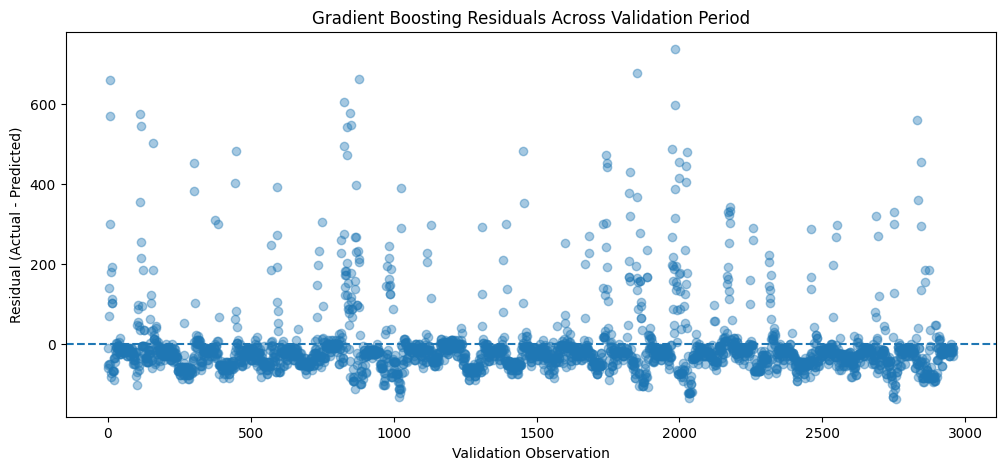

In [149]:
plt.figure(figsize=(12, 5))

plt.scatter(
    range(len(error_analysis)),
    error_analysis["residual"],
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Validation Observation")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Gradient Boosting Residuals Across Validation Period")

plt.show()

In [150]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_gbr.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance.head(15)

,feature,importance
29,hour_sin,0.294751
30,hour_cos,0.261420
0,lights,0.179461
5,T3,0.146818
27,month,0.036561
32,dow_cos,0.032392
17,T9,0.016609
11,T6,0.005214
4,RH_2,0.004466
12,RH_6,0.004036


In [151]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    best_gbr,
    X_val,
    y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance": perm_importance.importances_mean,
    "std": perm_importance.importances_std
})

perm_df = perm_df.sort_values(
    "importance",
    ascending=False
)

perm_df.head(15)

,feature,importance,std
30,hour_cos,5.508269,0.298262
29,hour_sin,5.252163,0.307313
5,T3,3.732388,0.402719
0,lights,0.268044,0.173006
12,RH_6,0.070122,0.034469
24,Tdewpoint,0.026510,0.013401
4,RH_2,0.004351,0.005592
3,T2,0.000000,0.000000
2,RH_1,0.000000,0.000000
15,T8,0.000000,0.000000


In [152]:
perm_df.head(15)

,feature,importance,std
30,hour_cos,5.508269,0.298262
29,hour_sin,5.252163,0.307313
5,T3,3.732388,0.402719
0,lights,0.268044,0.173006
12,RH_6,0.070122,0.034469
24,Tdewpoint,0.026510,0.013401
4,RH_2,0.004351,0.005592
3,T2,0.000000,0.000000
2,RH_1,0.000000,0.000000
15,T8,0.000000,0.000000


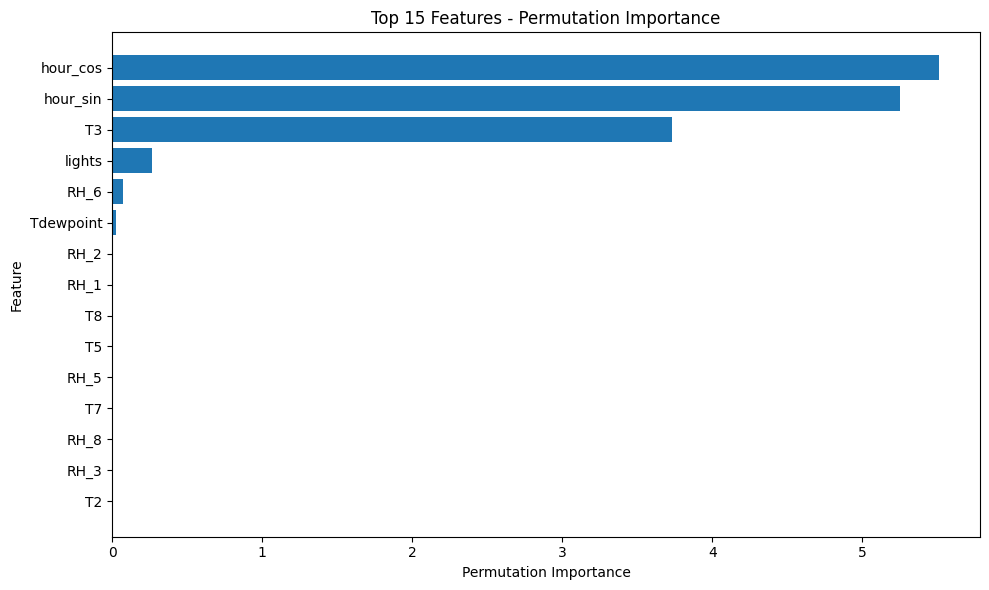

In [153]:
top_perm = perm_df.head(15).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_perm["feature"],
    top_perm["importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features - Permutation Importance")

plt.tight_layout()
plt.show()

### Permutation Importance

Permutation importance indicated that the cyclical time-of-day features (`hour_cos` and `hour_sin`) were the most influential predictors of validation performance, followed by room temperature (`T3`).

The substantial importance of the hour features suggests that appliance energy consumption follows meaningful daily usage patterns. `lights`, `RH_6`, and `Tdewpoint` provided smaller contributions, while many other temperature and humidity variables had relatively little individual permutation importance.

These results describe the features the trained model relied upon for prediction and should not be interpreted as evidence of causal relationships. Additionally, correlated predictors may share or substitute predictive information, which can reduce their individual permutation importance.

### Final Model Selection

Tuned Gradient Boosting was selected for final evaluation. It achieved the lowest validation RMSE (84.87) and highest validation R² (0.153) among the evaluated models.

Ridge Regression produced a slightly better cross-validation RMSE (95.66 versus 97.36 for Gradient Boosting), indicating that the performance difference between the strongest models was small. Therefore, Gradient Boosting was selected based on its held-out validation performance rather than assuming that its greater complexity guarantees superior performance.

The final model will now be evaluated once on the previously untouched test set.

In [154]:
gbr_test_pred = best_gbr.predict(X_test)

test_mae = mean_absolute_error(y_test, gbr_test_pred)
test_rmse = mean_squared_error(y_test, gbr_test_pred) ** 0.5
test_r2 = r2_score(y_test, gbr_test_pred)

print("Final Gradient Boosting - Test Set")
print(f"MAE:  {test_mae:.2f}")
print(f"RMSE: {test_rmse:.2f}")
print(f"R²:   {test_r2:.3f}")

Final Gradient Boosting - Test Set
MAE:  63.49
RMSE: 90.42
R²:   0.010


### Final Test Performance

The selected Gradient Boosting model was evaluated once on the previously untouched test set. It achieved an MAE of 63.49 Wh, RMSE of 90.42 Wh, and R² of 0.010.

Performance was weaker than on the validation set, where the model achieved an MAE of 48.07 Wh, RMSE of 84.87 Wh, and R² of 0.153. The near-zero test R² indicates that the model explained very little of the variation in appliance energy consumption during the final unseen period.

Combined with the earlier error analysis, these results demonstrate that predicting appliance energy consumption across future time periods remains challenging, particularly for relatively rare high-consumption events.

The test set was used only for final evaluation, and no additional model tuning was performed after observing these results.

In [155]:
test_errors = pd.DataFrame({
    "actual": y_test,
    "predicted": gbr_test_pred
})

test_errors["residual"] = (
    test_errors["actual"] - test_errors["predicted"]
)

test_errors["absolute_error"] = (
    test_errors["residual"].abs()
)

test_errors.sort_values(
    "absolute_error",
    ascending=False
).head(10)

,actual,predicted,residual,absolute_error
19582,850,172.406054,677.593946,677.593946
19541,820,171.361098,648.638902,648.638902
18820,790,154.162239,635.837761,635.837761
18830,720,171.361098,548.638902,548.638902
19581,710,172.406054,537.593946,537.593946
17658,660,137.674128,522.325872,522.325872
19685,660,171.361098,488.638902,488.638902
17677,600,137.674128,462.325872,462.325872
19695,620,171.361098,448.638902,448.638902
17696,620,171.361098,448.638902,448.638902


### Final Test Error Analysis

The final test-set error analysis confirmed the pattern previously observed on the validation data. The largest prediction errors were consistently associated with high appliance-energy-consumption observations.

For example, an actual consumption value of 850 Wh was predicted as approximately 172 Wh, resulting in an underprediction of approximately 678 Wh. Similar large underpredictions occurred throughout the ten largest absolute test errors.

The persistence of this pattern across both validation and test periods indicates that the model has difficulty capturing relatively rare high-demand events. Although the model performs more effectively within the common consumption range, its predictions tend to remain compressed toward moderate values during extreme consumption periods.

## Conclusion

This project evaluated multiple regression approaches for forecasting household appliance energy consumption using a chronological train-validation-test framework.

Linear Regression was used as an initial benchmark, followed by Ridge, Lasso, and Elastic Net regularization. Nonlinear approaches including Decision Tree, Random Forest, and Gradient Boosting were subsequently evaluated and tuned using time-series cross-validation.

Hyperparameter tuning substantially reduced overfitting in the tree-based models. The tuned Gradient Boosting model achieved the strongest held-out validation performance, with an RMSE of 84.87 Wh and R² of 0.153, and was therefore selected for final evaluation.

On the previously untouched test set, the model achieved:

- MAE: 63.49 Wh
- RMSE: 90.42 Wh
- R²: 0.010

The deterioration from validation to test performance demonstrates the difficulty of generalizing appliance-energy predictions across future time periods.

Error analysis revealed an important limitation: the model consistently underpredicted high-consumption events. This behavior appeared in both the validation and test sets, indicating that relatively rare energy-demand spikes were not adequately captured by the model.

Permutation importance showed that cyclical time-of-day variables were among the most influential predictors, highlighting the importance of daily usage patterns in appliance energy consumption.

Overall, the project demonstrates that model complexity alone does not guarantee better generalization. Careful chronological validation, hyperparameter regularization, error analysis, and transparent reporting of model limitations are essential when developing predictive models for time-dependent data.